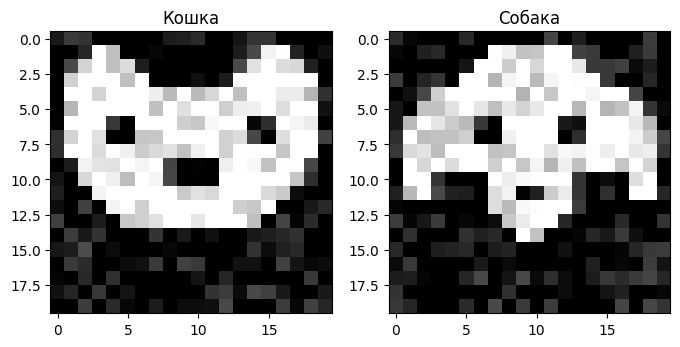

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Шаблон кошки
cat = [
    "00000000000000000000",
    "00011000000000011000",
    "00111100000000111100",
    "01111110000001111110",
    "01111111111111111110",
    "01111111111111111110",
    "01110011111111001110",
    "01110011111111001110",
    "01111111111111111110",
    "00111111000011111100",
    "00111111000011111100",
    "00011111111111111000",
    "00001111111111110000",
    "00000111111111100000",
    "00000000000000000000",
    "00000000000000000000",
    "00000000000000000000",
    "00000000000000000000",
    "00000000000000000000",
    "00000000000000000000"
]

# Шаблон собаки
dog=[
    "00000000000000000000",
    "00000001111110000000",
    "00000011111111000000",
    "00000111111111100000",
    "00011111111111111000",
    "00111111111111111100",
    "01111100111100111110",
    "01111100111100111110",
    "01111111111111111110",
    "01111111111111111110",
    "01100001111110000110",
    "01100001100110000110",
    "00000001111110000000",
    "00000000111100000000",
    "00000000011000000000",
    "00000000000000000000",
    "00000000000000000000",
    "00000000000000000000",
    "00000000000000000000",
    "00000000000000000000"
]

# Перевод строки в цифры
def matrix(template):
    return np.array([[int(i) for i in row] for row in template])

cat_template=matrix(cat)
dog_template=matrix(dog)

x=[]
y=[]

with open("dataset.dat",'w') as f:
  for i in range(40):
    if i<20:
      # Берём шаблон кошки + шум
      img=cat_template+np.random.uniform(-0.3,0.3,(20,20))
      y_i=0
    else:
      # Берём шаблон собаки + шум
      img=dog_template+np.random.uniform(-0.3,0.3,(20,20))
      y_i=1

    img=np.clip(img,0,1)
    x_flat=np.round(img.flatten(),2)

    x.append(x_flat)
    y.append(y_i)

    line=" ".join(map(str,x_flat))+f"{y}\n"
    f.write(line)

(предсказал
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.imshow(x[0].reshape(20,20),cmap='gray')
plt.title("Кошка")

plt.subplot(1, 2, 2)
plt.imshow(x[20].reshape(20,20), cmap='gray')
plt.title("Собака")
plt.show()

# Обучение

In [ ]:
from sklearn.model_selection import train_test_split
X=np.array(x)
Y=np.array(y)
xtr,xtest,ytr,ytest=train_test_split(X,Y)

# Решающее дерево

In [ ]:
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
import graphviz

clf_tree=DecisionTreeClassifier()
clf_tree.fit(xtr,ytr)
print(f"Tree score: {clf_tree.score(xtest,ytest)}")

dot_data = tree.export_graphviz(clf_tree, out_file=None)
graph = graphviz.Source(dot_data)
graph.render("tree")

Tree score: 1.0


'tree.pdf'

# Метод опорных векторов

In [ ]:
from sklearn.svm import SVC

clf_svm=SVC(kernel='linear')
clf_svm.fit(xtr,ytr)
print(f"SVM score: {clf_svm.score(xtest,ytest)}")

SVM score: 1.0


# Метод главных компонент + Решающее дерево

In [ ]:
from sklearn.decomposition import PCA

pca=PCA()
xtr_pca=pca.fit_transform(xtr)
xtest_pca=pca.transform(xtest)

clf_pca=DecisionTreeClassifier()
clf_pca.fit(xtr_pca,ytr)
print(f"PCA score: {clf_svm.score(xtest,ytest)}")

dot_data = tree.export_graphviz(clf_pca, out_file=None)
graph = graphviz.Source(dot_data)
graph.render("pca_tree")

PCA score: 1.0


'pca_tree.pdf'

# Ансамблевый метод

In [ ]:
from sklearn.ensemble import RandomForestClassifier

clf_rf=RandomForestClassifier(n_estimators=10,max_depth=2)
clf_rf.fit(xtr,ytr)
print(f"RFC score: {clf_svm.score(xtest,ytest)}")

RFC score: 1.0


# Замена пикселя

Before: 1, True class: 1
After: 0


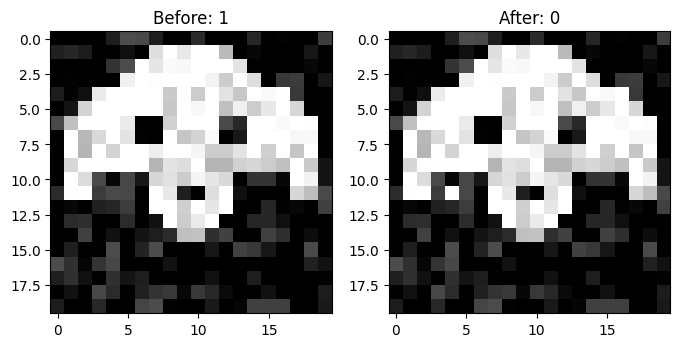

In [ ]:
img=xtest[0].copy()
true_class=ytest[0]

answer_before=clf_tree.predict([img])[0]
print(f"Before: {answer_before}, True class: {true_class}")

main_pixel=clf_tree.tree_.feature[0]

if img[main_pixel] > 0.5:
    img[main_pixel] = 0.0
else:
    img[main_pixel] = 1.0

answer_after=clf_tree.predict([img])[0]
print(f"After: {answer_after}")

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(xtest[0].reshape(20,20), cmap='gray')
plt.title(f"Before: {answer_before}")

plt.subplot(1, 2, 2)
plt.imshow(img.reshape(20,20), cmap='gray')
plt.title(f"After: {answer_after}")
plt.show()